# PPO - Lunar Lander

## 0. Setup, seeds, hyperparameters (with reasons)

| Hyperparameter | Value | Why |
|---|---|---|
| `n_envs` | 16 | 16 lunar landers play in parallel: more varied data per update, and stable advantages |
| `n_steps` | 1024 | steps per env per rollout, so a rollout = 16 x 1024 = **16 384 transitions**. Long enough to contain many full episodes |
| `total_steps` | 1 000 000 | budget in **environment steps** (not episodes): PPO collects fixed-size rollouts, so steps are the natural unit, and it makes the comparison with DQN fair |
| `gamma` | 0.999 | a landing can take 300-500 steps; with 0.99 a reward 500 steps away is worth 0.99^500 = 0.7%, with 0.999 it is still worth 61%. The agent must "see" the +100 of the landing |
| `gae_lambda` | 0.98 | bias / variance trade-off of GAE: close to 1 = uses the real returns (low bias), a bit below 1 = smoother |
| `n_epochs` | 4 | each rollout is reused 4 times; more epochs = the policy drifts too far from the one that collected the data |
| `minibatch_size` | 64 | many small gradient steps (16384 / 64 x 4 = 1024 per rollout) |
| `clip_eps` | 0.2 | standard value of the PPO paper: the probability of an action can only change by +-20% per update |
| `lr` | 3e-4 | standard Adam learning rate for PPO |
| `vf_coef` | 0.5 | weight of the critic loss in the total loss |
| `ent_coef` | 0.01 | small bonus for randomness, so the policy does not become certain too early |
| `max_grad_norm` | 0.5 | gradient clipping: protects against one huge update |
| `hidden` | 64 | two hidden layers of 64 neurons: the state has only 8 values, a small MLP is enough |

These values come from a first failed attempt (see section 13) and from the reference values used for LunarLander in the RL community (rl-baselines3-zoo).

In [43]:
# --- Section 0 : imports, seed, hyperparametres ---
import os, json, time
import numpy as np
import torch
import torch.nn as nn
from torch.distributions import Categorical
import matplotlib.pyplot as plt

from common import (
    make_env, set_seed, run_episode, evaluate,
    plot_training, moving_average, end_reason, ENV_ID,
)

# Petits reseaux -> 1 seul thread CPU est plus rapide (moins de coordination entre threads)
torch.set_num_threads(1)

SEEDS = [0, 1, 2]      # protocole multi-seed : SEEDS[0] = seed principale
SEED = SEEDS[0]
set_seed(SEED)

os.makedirs("models/runs", exist_ok=True)   # modeles intermediaires (ignores par git)
os.makedirs("results", exist_ok=True)       # courbes + chiffres exportes

# Tous les reglages au meme endroit (justifies dans le tableau au-dessus)
HP = dict(
    n_envs=16,            # 16 fusees en parallele
    n_steps=1024,         # pas par fusee avant chaque mise a jour
    total_steps=1_000_000,# budget total d'entrainement (en pas d'environnement)
    gamma=0.999,          # importance du futur
    gae_lambda=0.98,      # lissage de l'avantage (GAE)
    n_epochs=4,           # nb de passes sur chaque rollout
    minibatch_size=64,    # taille des mini-lots
    clip_eps=0.2,         # ceinture de securite du ratio
    lr=3e-4,              # vitesse d'apprentissage
    anneal_lr=False,      # (option) faire baisser lr au cours du temps
    vf_coef=0.5,          # poids de la loss du coach (critic)
    ent_coef=0.01,        # poids du bonus de curiosite (entropie)
    max_grad_norm=0.5,    # limite la taille des gradients
    hidden=64,            # neurones par couche cachee
    eval_every=2,         # evaluer toutes les 2 mises a jour (~32k pas)
    eval_episodes=10,     # nb d'episodes pour l'eval rapide pendant l'entrainement
)
print(json.dumps(HP, indent=1))

{
 "n_envs": 16,
 "n_steps": 1024,
 "total_steps": 1000000,
 "gamma": 0.999,
 "gae_lambda": 0.98,
 "n_epochs": 4,
 "minibatch_size": 64,
 "clip_eps": 0.2,
 "lr": 0.0003,
 "anneal_lr": false,
 "vf_coef": 0.5,
 "ent_coef": 0.01,
 "max_grad_norm": 0.5,
 "hidden": 64,
 "eval_every": 2,
 "eval_episodes": 10
}


## 1. Environment initialization

* Training uses `render_mode=None` (no window): rendering every frame is very slow.
* The state size and the number of actions are **read from the environment**, never hard-coded.
* **Parallel environments**: instead of `gym.vector`, we keep a simple Python list of `n_envs` independent environments and step them one after the other. The neural network still processes the 16 states **in one batch**. Doing it by hand lets us call `end_reason()` on each env *before* resetting it, so the crash / out of viewport / at rest / truncated statistics stay exact.

In [44]:
# --- Section 1 : creation des environnements ---
env = make_env()                                  # env "temoin" pour lire les dimensions
STATE_DIM = env.observation_space.shape[0]        # 8 infos du tableau de bord
N_ACTIONS = env.action_space.n                    # 4 boutons
env.close()
print(f"STATE_DIM={STATE_DIM}  N_ACTIONS={N_ACTIONS}")

def make_envs(n_envs, seed):
    """Cree n_envs Lunar Lander independants, chacun avec sa propre seed."""
    envs = [make_env() for _ in range(n_envs)]                    # pas de rendu = rapide
    states = np.stack([e.reset(seed=seed * 1000 + i)[0]           # 1er etat de chaque env
                       for i, e in enumerate(envs)])
    for i, e in enumerate(envs):
        e.action_space.seed(seed * 1000 + i)
    return envs, states

envs, states = make_envs(4, SEED)
print("states batch shape:", states.shape)       # (4, 8) = 4 fusees x 8 infos
for e in envs: e.close()

STATE_DIM=8  N_ACTIONS=4
states batch shape: (4, 8)


## 1b. Random baseline

In [45]:
# --- Agent aleatoire : 100 episodes, aucun apprentissage ---
env_baseline = make_env(seed=SEED)

def random_policy(state):
    return env_baseline.action_space.sample()     # appuie sur un bouton au hasard

baseline = evaluate(env_baseline, random_policy, n_episodes=100, seed=SEED)
env_baseline.close()
print(f"\nRandom baseline: mean={baseline['mean']:.1f}  std={baseline['std']:.1f}")
print("Target to beat: mean >= 200 (spec)")

Eval over 100 episodes (no exploration):
  mean=-191.96  std=114.55  min=-462.47  max=8.26
  end reasons: {'crash': 92, 'out_of_viewport': 8}

Random baseline: mean=-192.0  std=114.6
Target to beat: mean >= 200 (spec)


## 2. Actor, critic, advantage, 3 loss terms (explanation)

**DQN** learns a *score* for each action and deduces its behaviour from it (value-based).
**PPO** learns the *behaviour directly* (policy-based): for each state, a probability for each action.

| Element | Role | Analogy |
|---|---|---|
| **Actor** $\pi_\theta(a\mid s)$ | outputs one probability per action; the action is **sampled** from it, so exploration is built in (no epsilon) | the player |
| **Critic** $V_\phi(s)$ | predicts the total reward expected from state $s$ | the coach predicting the final score |
| **Advantage** $A_t$ | how much better the action was than what the critic expected. $A>0$: make it more likely. $A<0$: less likely | the "surprise" |
| **Rollout** | 16 x 1024 transitions collected with the current policy, used for 4 epochs then **thrown away** | one filmed training session |

**Generalized Advantage Estimation (GAE)**

$$\delta_t = r_t + \gamma V(s_{t+1})(1-d_t) - V(s_t) \qquad A_t = \delta_t + \gamma\lambda(1-d_t)A_{t+1}$$

$\delta_t$ is the one-step surprise; GAE sums the future surprises with a decay $\gamma\lambda$. $\lambda=0$ would only trust the critic (biased), $\lambda=1$ would only trust real returns (noisy). The **return** used to train the critic is $R_t = A_t + V(s_t)$.

**The loss has 3 terms** (we minimise it):

$$L = \underbrace{-\mathbb{E}\big[\min(\rho_t A_t,\ \text{clip}(\rho_t, 1-\epsilon, 1+\epsilon)A_t)\big]}_{\text{1. clipped policy loss}} + c_v\underbrace{\mathbb{E}\big[(V(s_t)-R_t)^2\big]}_{\text{2. value loss (MSE)}} - c_e\underbrace{\mathbb{E}\big[\mathcal{H}(\pi(\cdot\mid s_t))\big]}_{\text{3. entropy bonus}}$$

1. **Clipped policy loss**: $\rho_t = \pi_{new}(a_t|s_t)/\pi_{old}(a_t|s_t)$ is the ratio. It pushes up actions with $A>0$, but the `clip` + `min` stop the gain once the ratio leaves $[0.8, 1.2]$: one update cannot change the policy too much (the "seat belt").
2. **Value loss**: MSE between the critic's prediction and the actual return. It makes the coach more accurate, which makes the advantages more accurate.
3. **Entropy bonus**: entropy measures how random the policy is. It is *subtracted*, so minimising the loss *increases* the entropy, which keeps the agent exploring.

**Terminated vs truncated.** `terminated` (crash, out of screen, at rest) means there is no future: $d_t=1$, no bootstrap. `truncated` (1000-step limit) means the lander could have continued: we cut the episode in the rollout but add $\gamma V(s_{final})$ to the last reward, so the future is not wrongly counted as zero.

## 3. Network architecture

**Choice: two separate networks** (actor and critic, each 8 -> 64 -> 64 -> output, `tanh`).
* Why separate: the critic's values are large (hundreds) while the actor's outputs are small logits. With a shared body the value loss gradients would dominate and disturb the policy. Separate nets avoid having to tune that balance; the cost (a second small MLP) is negligible.
* `tanh` and **orthogonal initialisation** are the standard PPO choices. The last actor layer is initialised very small (std 0.01) so that at the start all 4 actions have ~25% probability (maximum exploration).

In [46]:
# --- Section 3 : reseaux Actor + Critic ---
def layer_init(layer, std=np.sqrt(2), bias=0.0):
    """Initialisation orthogonale (standard PPO) : gradients plus stables au debut."""
    nn.init.orthogonal_(layer.weight, std)
    nn.init.constant_(layer.bias, bias)
    return layer

class ActorCritic(nn.Module):
    def __init__(self, state_dim, n_actions, hidden=64):
        super().__init__()
        # ACTOR (le joueur) : etat -> 4 "logits" (scores bruts -> probabilites)
        self.actor = nn.Sequential(
            layer_init(nn.Linear(state_dim, hidden)), nn.Tanh(),
            layer_init(nn.Linear(hidden, hidden)), nn.Tanh(),
            layer_init(nn.Linear(hidden, n_actions), std=0.01),  # petit -> ~25% par action au debut
        )
        # CRITIC (le coach) : etat -> 1 nombre = score attendu V(s)
        self.critic = nn.Sequential(
            layer_init(nn.Linear(state_dim, hidden)), nn.Tanh(),
            layer_init(nn.Linear(hidden, hidden)), nn.Tanh(),
            layer_init(nn.Linear(hidden, 1), std=1.0),
        )

    def forward(self, x):
        """Renvoie (logits de l'actor, valeur du critic)."""
        return self.actor(x), self.critic(x).squeeze(-1)

    def act(self, x):
        """Pendant l'entrainement : on TIRE AU SORT l'action (exploration integree)."""
        logits, value = self(x)
        dist = Categorical(logits=logits)        # distribution de probas sur les 4 actions
        action = dist.sample()                   # tirage au sort
        return action, dist.log_prob(action), value

    def evaluate_actions(self, x, actions):
        """Pendant la mise a jour : proba (log) des actions deja jouees + entropie + valeur."""
        logits, value = self(x)
        dist = Categorical(logits=logits)
        return dist.log_prob(actions), dist.entropy(), value

net = ActorCritic(STATE_DIM, N_ACTIONS, HP["hidden"])
print(net)
print("parameters:", sum(p.numel() for p in net.parameters()))
with torch.no_grad():
    logits, v = net(torch.zeros(1, STATE_DIM))
print("initial probabilities:", torch.softmax(logits, -1).numpy().round(3))  # ~0.25 partout

ActorCritic(
  (actor): Sequential(
    (0): Linear(in_features=8, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=4, bias=True)
  )
  (critic): Sequential(
    (0): Linear(in_features=8, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)
parameters: 9797
initial probabilities: [[0.25 0.25 0.25 0.25]]


## 4. Rollout storage + GAE

PPO **does not use a replay buffer**: it only learns from data collected by its current policy. The rollout storage holds, for each of the `n_steps x n_envs` transitions: state, action, **log-probability of the action**, reward, done, **critic value**, then the computed **advantages** and **returns**. It is emptied after each update. Everything is stored as tensors grouped by element (not a list of tuples).

In [47]:
# --- Section 4 : stockage du rollout + calcul GAE ---
class RolloutStorage:
    def __init__(self, n_steps, n_envs, state_dim):
        T, N = n_steps, n_envs
        # Un tableau (tensor) par element : forme (T pas, N envs)
        self.states     = torch.zeros(T, N, state_dim)
        self.actions    = torch.zeros(T, N, dtype=torch.long)
        self.log_probs  = torch.zeros(T, N)   # log proba de l'action AU MOMENT du jeu (pour le ratio)
        self.rewards    = torch.zeros(T, N)
        self.dones      = torch.zeros(T, N)   # 1 si l'episode s'est arrete apres ce pas
        self.values     = torch.zeros(T, N)   # prediction du coach V(s)
        self.advantages = torch.zeros(T, N)
        self.returns    = torch.zeros(T, N)
        self.t = 0                            # curseur : prochain pas a remplir

    def add(self, state, action, log_prob, reward, done, value):
        """Range 1 pas de jeu (pour les N envs d'un coup)."""
        self.states[self.t] = state
        self.actions[self.t] = action
        self.log_probs[self.t] = log_prob
        self.rewards[self.t] = reward
        self.dones[self.t] = done
        self.values[self.t] = value
        self.t += 1

    def compute_gae(self, last_value, gamma, lam):
        """Calcule l'avantage de chaque pas, en partant de la FIN du rollout."""
        gae = torch.zeros_like(last_value)
        for t in reversed(range(self.t)):
            # valeur de l'etat suivant (au dernier pas : on utilise last_value)
            next_value = last_value if t == self.t - 1 else self.values[t + 1]
            not_done = 1.0 - self.dones[t]                 # 0 si l'episode s'est arrete -> pas de futur
            # surprise d'un pas : (recompense + futur estime) - ce que le coach avait prevu
            delta = self.rewards[t] + gamma * next_value * not_done - self.values[t]
            # GAE : on additionne les surprises futures, de moins en moins (gamma*lambda)
            gae = delta + gamma * lam * not_done * gae
            self.advantages[t] = gae
        self.returns = self.advantages + self.values      # cible du coach

    def get_minibatches(self, minibatch_size):
        """Aplatit (T, N) -> (T*N) et renvoie des mini-lots melanges."""
        n = self.t * self.states.shape[1]
        flat = dict(
            states=self.states[:self.t].reshape(n, -1),
            actions=self.actions[:self.t].reshape(n),
            log_probs=self.log_probs[:self.t].reshape(n),
            advantages=self.advantages[:self.t].reshape(n),
            returns=self.returns[:self.t].reshape(n),
        )
        idx = torch.randperm(n)                             # melange
        for start in range(0, n, minibatch_size):
            mb = idx[start:start + minibatch_size]
            yield {k: v[mb] for k, v in flat.items()}

    def reset(self):
        self.t = 0                                          # on "jette" le rollout

# Petit test a la main : 1 env, 3 pas, gamma=lambda=1, le coach predit 0 partout
s = RolloutStorage(3, 1, STATE_DIM)
for r, d in [(1.0, 0), (1.0, 0), (1.0, 1)]:
    s.add(torch.zeros(1, STATE_DIM), torch.zeros(1, dtype=torch.long), torch.zeros(1),
          torch.tensor([r]), torch.tensor([float(d)]), torch.zeros(1))
s.compute_gae(torch.tensor([50.0]), gamma=1.0, lam=1.0)
print("advantages:", s.advantages.squeeze().tolist(), "-> expected [3, 2, 1] (50 ignored: episode ended)")

advantages: [3.0, 2.0, 1.0] -> expected [3, 2, 1] (50 ignored: episode ended)


## 5. PPO update

For each of the `n_epochs` passes over the rollout, and for each mini-batch:
1. recompute the log-probabilities of the stored actions with the **current** network, the entropy and the values;
2. normalise the advantages in the mini-batch (mean 0, std 1) for stable gradient sizes;
3. compute the 3 terms and the total loss, backpropagate, clip the gradient norm, step Adam.

We also log two health indicators: `clip_frac` (share of transitions where the clip was active) and `approx_kl` (how far the new policy is from the old one).

In [48]:
# --- Section 5 : mise a jour PPO (les 3 termes de la loss) ---
def ppo_update(model, optimizer, storage, hp):
    stats = dict(policy_loss=[], value_loss=[], entropy=[], clip_frac=[], approx_kl=[])
    for _ in range(hp["n_epochs"]):                         # on relit le rollout plusieurs fois
        for mb in storage.get_minibatches(hp["minibatch_size"]):
            new_log_probs, entropy, values = model.evaluate_actions(mb["states"], mb["actions"])

            # Avantages normalises (moyenne 0, ecart-type 1)
            adv = mb["advantages"]
            adv = (adv - adv.mean()) / (adv.std() + 1e-8)

            # Ratio = proba nouvelle / proba ancienne (via les log : exp(a - b) = a/b)
            log_ratio = new_log_probs - mb["log_probs"]
            ratio = log_ratio.exp()

            # 1) POLICY LOSS "clippee" : la ceinture de securite
            surr1 = ratio * adv
            surr2 = torch.clamp(ratio, 1 - hp["clip_eps"], 1 + hp["clip_eps"]) * adv
            policy_loss = -torch.min(surr1, surr2).mean()      # "-" car on MINIMISE

            # 2) VALUE LOSS : MSE entre la prediction du coach et le vrai retour
            value_loss = ((values - mb["returns"]) ** 2).mean()

            # 3) ENTROPIE : bonus de curiosite (soustrait -> on la fait monter)
            entropy_mean = entropy.mean()

            loss = policy_loss + hp["vf_coef"] * value_loss - hp["ent_coef"] * entropy_mean

            optimizer.zero_grad()
            loss.backward()                                      # calcule les gradients
            nn.utils.clip_grad_norm_(model.parameters(), hp["max_grad_norm"])
            optimizer.step()                                     # applique la correction

            # indicateurs de sante (pas utilises pour apprendre)
            with torch.no_grad():
                stats["policy_loss"].append(policy_loss.item())
                stats["value_loss"].append(value_loss.item())
                stats["entropy"].append(entropy_mean.item())
                stats["clip_frac"].append(((ratio - 1).abs() > hp["clip_eps"]).float().mean().item())
                stats["approx_kl"].append(((ratio - 1) - log_ratio).mean().item())
    return {k: float(np.mean(v)) for k, v in stats.items()}

## 6. Training loop

* **Budget**: `total_steps` environment steps, split into `total_steps // (n_envs x n_steps)` rollouts (= 61 updates).
* **When it learns**: once per complete rollout (every 16 384 transitions), never in the middle (on-policy).
* **Logs per episode**: total reward, number of steps, end reason (crash / out_of_viewport / at_rest / truncated), and the global step at which it ended.
* **Regular evaluation**: every `eval_every` updates, 10 episodes **without exploration** (argmax of the logits) on fixed seeds; the best version is saved (`save_path`). The final 100-episode evaluation (section 9) uses *other* seeds, so this selection does not bias it.

In [49]:
# --- Section 6 : boucle d'entrainement ---
def make_greedy_policy(model):
    """Politique d'EVALUATION : plus de tirage au sort, on prend l'action la plus probable."""
    def act_fn(state):
        with torch.no_grad():
            logits, _ = model(torch.as_tensor(state, dtype=torch.float32))
        return int(logits.argmax())
    return act_fn

def quick_eval(model, n_episodes, seed):
    """Eval rapide (sans exploration) pendant l'entrainement."""
    env = make_env()
    scores = [run_episode(env, make_greedy_policy(model), seed=seed + i).reward
              for i in range(n_episodes)]
    env.close()
    return float(np.mean(scores))

def train_ppo(hp, seed, save_path=None, verbose=True):
    set_seed(seed)
    envs, states = make_envs(hp["n_envs"], seed)
    model = ActorCritic(STATE_DIM, N_ACTIONS, hp["hidden"])
    optimizer = torch.optim.Adam(model.parameters(), lr=hp["lr"], eps=1e-5)
    storage = RolloutStorage(hp["n_steps"], hp["n_envs"], STATE_DIM)

    log = dict(ep_rewards=[], ep_lengths=[], ep_reasons=[], ep_end_step=[],
               policy_loss=[], value_loss=[], entropy=[], clip_frac=[], approx_kl=[],
               eval_steps=[], eval_scores=[])
    ep_reward = np.zeros(hp["n_envs"])                   # score en cours de chaque fusee
    ep_len = np.zeros(hp["n_envs"], dtype=int)           # nb de pas en cours de chaque fusee
    best_eval = -np.inf
    n_updates = hp["total_steps"] // (hp["n_envs"] * hp["n_steps"])
    global_step = 0
    t0 = time.time()

    for update in range(1, n_updates + 1):
        if hp["anneal_lr"]:                               # option : lr qui descend vers 0
            optimizer.param_groups[0]["lr"] = hp["lr"] * (1 - (update - 1) / n_updates)

        # ---------- 1. JOUER : remplir un rollout ----------
        storage.reset()
        for _ in range(hp["n_steps"]):
            s_t = torch.as_tensor(states, dtype=torch.float32)
            with torch.no_grad():
                actions, log_probs, values = model.act(s_t)       # 16 actions d'un coup
            rewards = np.zeros(hp["n_envs"], dtype=np.float32)
            dones = np.zeros(hp["n_envs"], dtype=np.float32)
            next_states = np.zeros_like(states)

            for i, env in enumerate(envs):
                ns, r, term, trunc, _ = env.step(int(actions[i]))
                ep_reward[i] += r; ep_len[i] += 1
                # TRUNCATED : la fusee aurait pu continuer -> on ajoute le futur estime
                if trunc and not term:
                    with torch.no_grad():
                        _, v_last = model(torch.as_tensor(ns, dtype=torch.float32))
                    r = r + hp["gamma"] * float(v_last)
                rewards[i] = r
                if term or trunc:                          # fin d'episode pour cette fusee
                    dones[i] = 1.0
                    log["ep_rewards"].append(float(ep_reward[i]))
                    log["ep_lengths"].append(int(ep_len[i]))
                    log["ep_reasons"].append(end_reason(env, term, trunc, ns))  # AVANT le reset
                    log["ep_end_step"].append(global_step + i + 1)
                    ep_reward[i] = 0.0; ep_len[i] = 0
                    ns, _ = env.reset()                    # nouvelle partie
                next_states[i] = ns

            storage.add(s_t, actions, log_probs, torch.as_tensor(rewards),
                        torch.as_tensor(dones), values)
            states = next_states
            global_step += hp["n_envs"]

        # ---------- 2. CALCULER les avantages ----------
        with torch.no_grad():
            _, last_value = model(torch.as_tensor(states, dtype=torch.float32))
        storage.compute_gae(last_value, hp["gamma"], hp["gae_lambda"])

        # ---------- 3. APPRENDRE ----------
        stats = ppo_update(model, optimizer, storage, hp)
        for k, v in stats.items():
            log[k].append(v)

        # ---------- 4. EVALUER + garder la meilleure version ----------
        if update % hp["eval_every"] == 0 or update == n_updates:
            score = quick_eval(model, hp["eval_episodes"], seed=10_000)
            log["eval_steps"].append(global_step); log["eval_scores"].append(score)
            if score > best_eval:
                best_eval = score
                if save_path:
                    torch.save(model.state_dict(), save_path)
            if verbose:
                ma = np.mean(log["ep_rewards"][-100:])
                print(f"step {global_step:>8} | ep {len(log['ep_rewards']):>5} | MA100 {ma:7.1f} | "
                      f"eval {score:7.1f} | best {best_eval:7.1f} | ent {stats['entropy']:.3f} | "
                      f"{time.time() - t0:5.0f}s")

    for e in envs:
        e.close()
    log["train_time"] = time.time() - t0
    log["best_eval"] = best_eval
    log["hp"] = hp
    log["seed"] = seed
    return model, log

def steps_to_200(log):
    """1er pas d'environnement ou l'eval rapide (sans exploration) atteint 200."""
    for s, sc in zip(log["eval_steps"], log["eval_scores"]):
        if sc >= 200:
            return int(s)
    return None

def save_log(log, path):
    with open(path, "w") as f:
        json.dump(log, f)

In [50]:
# --- Entrainement principal (seed 0) -> models/ppo.pt  (~5 min) ---
model, log = train_ppo(HP, SEED, save_path="models/ppo.pt")
save_log(log, f"results/ppo_seed{SEED}.json")
print(f"\ntraining time: {log['train_time']:.0f}s | best quick eval: {log['best_eval']:.1f} "
      f"| first eval >= 200 at step: {steps_to_200(log)}")

step    32768 | ep   344 | MA100  -141.8 | eval   -22.0 | best   -22.0 | ent 1.366 |     9s
step    65536 | ep   664 | MA100  -105.0 | eval -4349.6 | best   -22.0 | ent 1.330 |    18s
step    98304 | ep   951 | MA100   -83.6 | eval  -290.4 | best   -22.0 | ent 1.261 |    27s
step   131072 | ep  1212 | MA100   -41.4 | eval  -149.5 | best   -22.0 | ent 1.200 |    37s
step   163840 | ep  1434 | MA100    -7.5 | eval  -146.4 | best   -22.0 | ent 1.165 |    45s
step   196608 | ep  1604 | MA100     8.9 | eval  -162.0 | best   -22.0 | ent 1.146 |    54s
step   229376 | ep  1682 | MA100    28.5 | eval   -79.1 | best   -22.0 | ent 1.169 |    64s
step   262144 | ep  1748 | MA100    33.3 | eval    45.5 | best    45.5 | ent 1.167 |    74s
step   294912 | ep  1797 | MA100    50.5 | eval   141.0 | best   141.0 | ent 1.139 |    83s
step   327680 | ep  1849 | MA100    69.3 | eval    46.7 | best   141.0 | ent 1.076 |    93s
step   360448 | ep  1890 | MA100    83.0 | eval   155.6 | best   155.6 | ent 1.0

## 7. Training curves: reward + MA, length, policy loss, value loss, entropy

* **Reward per episode** (and its 100-episode moving average): measured *with* exploration (sampled actions), so it is lower than the greedy evaluation score.
* **Episode length**: long episodes at the start = the lander hovers (afraid to land); they get shorter when it learns to land quickly.
* **Policy loss / value loss / entropy**: one point per update. The entropy should decrease slowly (the policy becomes more confident) but never collapse to 0.

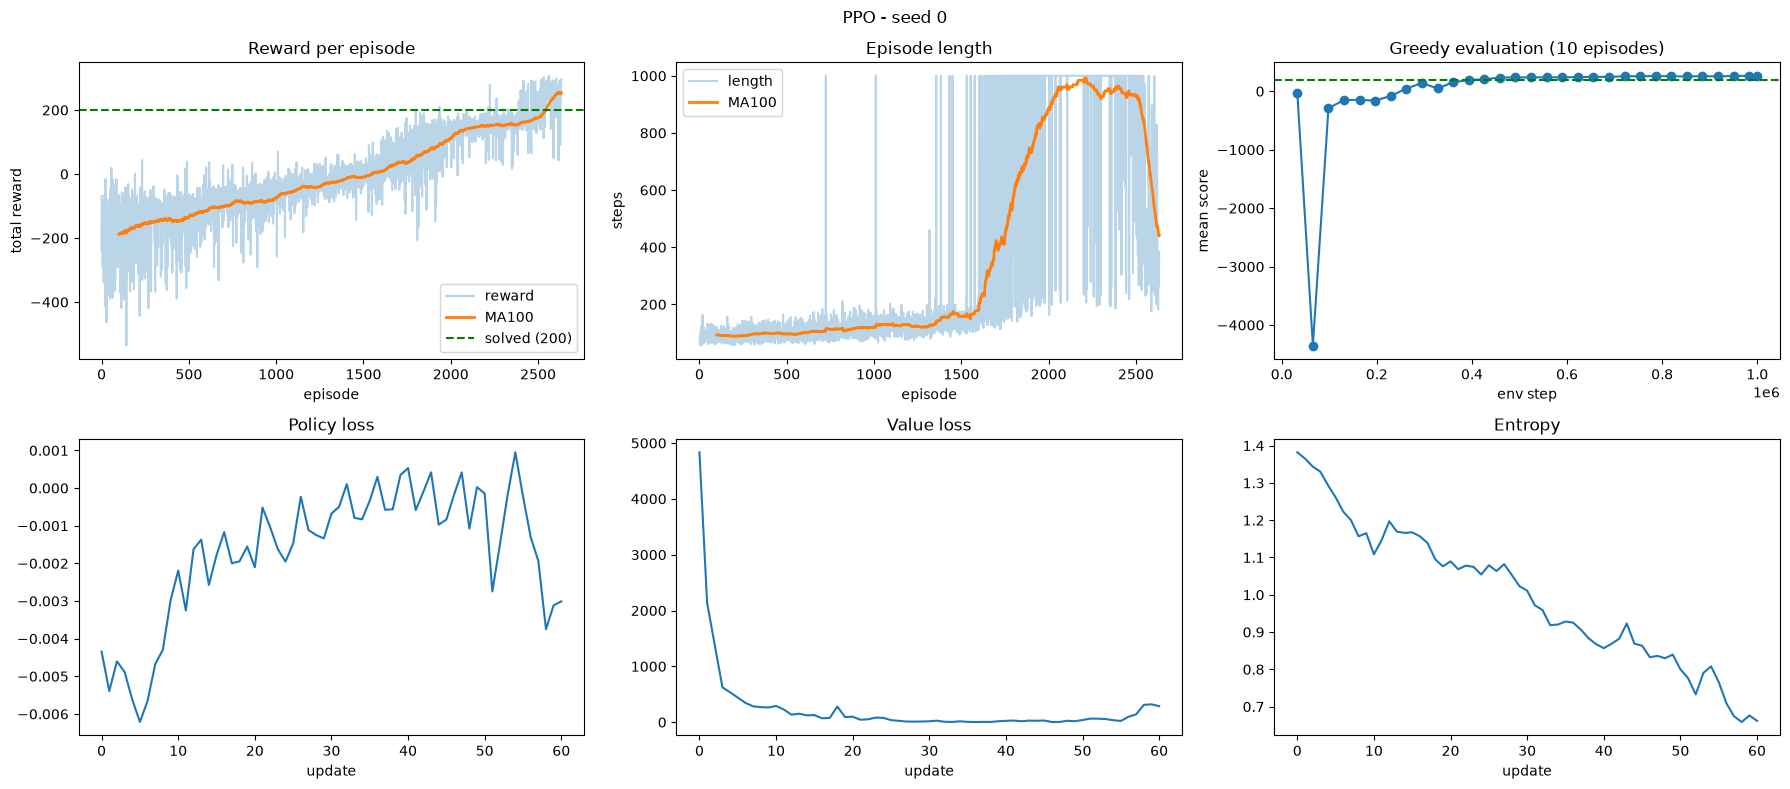

In [51]:
# --- Section 7 : courbes d'entrainement ---
def plot_ppo(log, title="PPO", save=None, window=100):
    fig, ax = plt.subplots(2, 3, figsize=(18, 8))
    fig.suptitle(title)
    r = np.array(log["ep_rewards"]); l = np.array(log["ep_lengths"])

    ax[0, 0].plot(r, alpha=0.3, label="reward")
    ax[0, 0].plot(np.arange(window - 1, len(r)), moving_average(r, window), lw=2, label=f"MA{window}")
    ax[0, 0].axhline(200, color="green", ls="--", label="solved (200)")
    ax[0, 0].set(title="Reward per episode", xlabel="episode", ylabel="total reward"); ax[0, 0].legend()

    ax[0, 1].plot(l, alpha=0.3, label="length")
    ax[0, 1].plot(np.arange(window - 1, len(l)), moving_average(l, window), lw=2, label=f"MA{window}")
    ax[0, 1].set(title="Episode length", xlabel="episode", ylabel="steps"); ax[0, 1].legend()

    ax[0, 2].plot(log["eval_steps"], log["eval_scores"], marker="o")
    ax[0, 2].axhline(200, color="green", ls="--")
    ax[0, 2].set(title="Greedy evaluation (10 episodes)", xlabel="env step", ylabel="mean score")

    ax[1, 0].plot(log["policy_loss"]); ax[1, 0].set(title="Policy loss", xlabel="update")
    ax[1, 1].plot(log["value_loss"]); ax[1, 1].set(title="Value loss", xlabel="update")
    ax[1, 2].plot(log["entropy"]); ax[1, 2].set(title="Entropy", xlabel="update")
    plt.tight_layout()
    if save:
        plt.savefig(save, dpi=100)
    plt.show()

plot_ppo(log, f"PPO - seed {SEED}", save="results/ppo_training.png")

## 8. Termination statistics

Why did each training episode end? The share of `at_rest` (successful landings) should grow, `crash` and `out_of_viewport` should disappear.

all training                      crash  out_of_viewport          at_rest        truncated
                           1752 (66.5%)       33 ( 1.3%)      132 ( 5.0%)      717 (27.2%)
first 500 episodes                crash  out_of_viewport          at_rest        truncated
                            477 (95.4%)       23 ( 4.6%)        0 ( 0.0%)        0 ( 0.0%)
last 500 episodes                 crash  out_of_viewport          at_rest        truncated
                             18 ( 3.6%)        0 ( 0.0%)      128 (25.6%)      354 (70.8%)


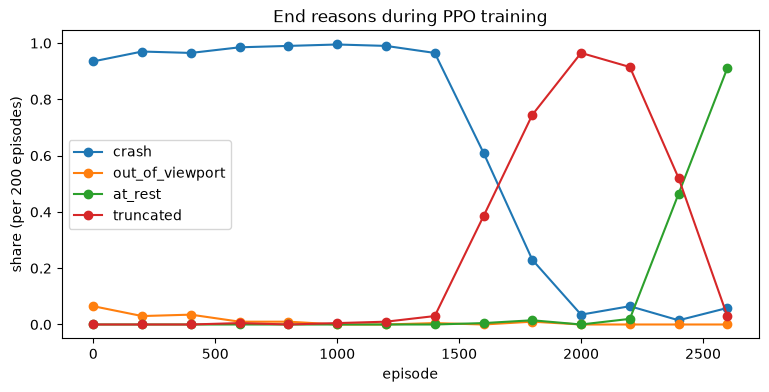

In [52]:
# --- Section 8 : pourquoi les episodes se terminent ---
from collections import Counter
REASONS = ["crash", "out_of_viewport", "at_rest", "truncated"]

def termination_table(reasons, label):
    c = Counter(reasons); n = len(reasons)
    print(f"{label:<22}" + "".join(f"{k:>17}" for k in REASONS))
    print(f"{'':<22}" + "".join(f"{c.get(k, 0):>9} ({100 * c.get(k, 0) / n:4.1f}%)" for k in REASONS))

termination_table(log["ep_reasons"], "all training")
termination_table(log["ep_reasons"][:500], "first 500 episodes")
termination_table(log["ep_reasons"][-500:], "last 500 episodes")

# Evolution : proportion de chaque fin par tranche de 200 episodes
chunk = 200
reasons = np.array(log["ep_reasons"])
xs = np.arange(0, len(reasons), chunk)
plt.figure(figsize=(9, 4))
for k in REASONS:
    plt.plot(xs, [np.mean(reasons[i:i + chunk] == k) for i in xs], marker="o", label=k)
plt.xlabel("episode"); plt.ylabel(f"share (per {chunk} episodes)")
plt.title("End reasons during PPO training"); plt.legend(); plt.savefig("results/ppo_end_reasons.png"); plt.show()

## 9. Evaluation: 100 episodes

We reload the **saved** model (`models/ppo.pt`, the best checkpoint) and play 100 episodes with the greedy policy (argmax of the actor's logits, no sampling).

Eval over 100 episodes (no exploration):
  mean=266.21  std=21.16  min=225.33  max=302.81
  end reasons: {'at_rest': 100}
SOLVED (threshold 200)


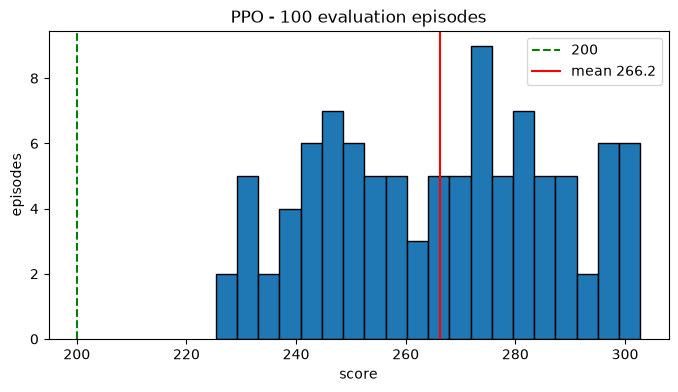

In [53]:
# --- Section 9 : evaluation officielle (100 episodes, sans exploration) ---
best = ActorCritic(STATE_DIM, N_ACTIONS, HP["hidden"])
best.load_state_dict(torch.load("models/ppo.pt"))       # on recharge le modele SAUVEGARDE
best.eval()

eval_env = make_env()
eval_stats = evaluate(eval_env, make_greedy_policy(best), n_episodes=100, seed=0)
eval_env.close()
print("SOLVED" if eval_stats["mean"] >= 200 else "NOT SOLVED", "(threshold 200)")

plt.figure(figsize=(8, 4))
plt.hist(eval_stats["rewards"], bins=20, edgecolor="black")
plt.axvline(200, color="green", ls="--", label="200")
plt.axvline(eval_stats["mean"], color="red", label=f"mean {eval_stats['mean']:.1f}")
plt.xlabel("score"); plt.ylabel("episodes"); plt.title("PPO - 100 evaluation episodes"); plt.legend()
plt.savefig("results/ppo_eval_hist.png"); plt.show()

## 10. Several seeds

Same hyperparameters, seeds 1 and 2 (seed 0 is already trained above). We check that the result is not luck. The models of these runs go to `models/runs/` (ignored by git).


===== seed 1 =====
Eval over 100 episodes (no exploration):
  mean=262.45  std=20.98  min=224.09  max=305.05
  end reasons: {'at_rest': 100}

===== seed 2 =====
Eval over 100 episodes (no exploration):
  mean=245.97  std=43.23  min=18.41  max=305.54
  end reasons: {'at_rest': 94, 'truncated': 5, 'crash': 1}

seed  eval mean     std  steps to 200  time (s)
   0      266.2    21.2        425984       291
   1      262.4    21.0        327680       279
   2      246.0    43.2        524288       314

across seeds: 258.2 +- 8.8


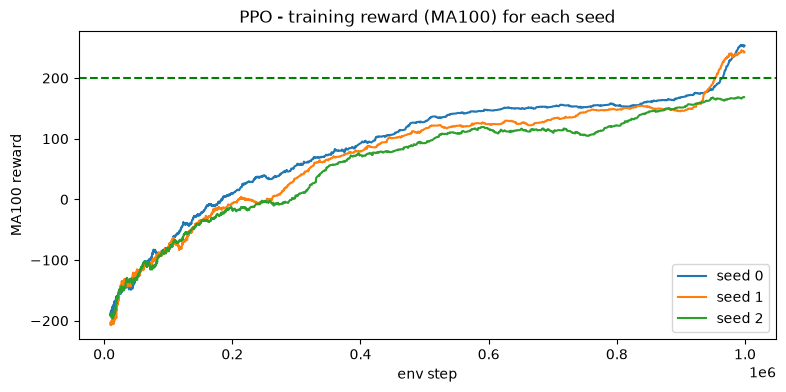

In [54]:
# --- Section 10 : multi-seed (~10 min) ---
seed_logs = {SEED: log}
seed_evals = {SEED: eval_stats}
for s in SEEDS[1:]:
    print(f"\n===== seed {s} =====")
    path = f"models/runs/ppo_seed{s}.pt"
    _, lg = train_ppo(HP, s, save_path=path, verbose=False)
    save_log(lg, f"results/ppo_seed{s}.json")
    m = ActorCritic(STATE_DIM, N_ACTIONS, HP["hidden"]); m.load_state_dict(torch.load(path))
    e = make_env(); seed_evals[s] = evaluate(e, make_greedy_policy(m), 100, seed=0); e.close()
    seed_logs[s] = lg

print(f"\n{'seed':>4} {'eval mean':>10} {'std':>7} {'steps to 200':>13} {'time (s)':>9}")
for s in SEEDS:
    print(f"{s:>4} {seed_evals[s]['mean']:>10.1f} {seed_evals[s]['std']:>7.1f} "
          f"{str(steps_to_200(seed_logs[s])):>13} {seed_logs[s]['train_time']:>9.0f}")
means = [seed_evals[s]["mean"] for s in SEEDS]
print(f"\nacross seeds: {np.mean(means):.1f} +- {np.std(means):.1f}")

plt.figure(figsize=(9, 4))
for s in SEEDS:
    lg = seed_logs[s]
    plt.plot(lg["ep_end_step"][99:], moving_average(lg["ep_rewards"], 100), label=f"seed {s}")
plt.axhline(200, color="green", ls="--"); plt.xlabel("env step"); plt.ylabel("MA100 reward")
plt.title("PPO - training reward (MA100) for each seed"); plt.legend()
plt.savefig("results/ppo_seeds.png"); plt.show()

## 11. Experiment: variations

**Question**: what does the "seat belt" (`clip_eps`) change?
**Prediction (written before running)**: `0.1` = very small steps, slower but smoother learning; `0.3` = bigger steps, faster at first but less stable.
Only `clip_eps` changes; everything else (including seed 0) is identical to the main run (`clip_eps=0.2`).


===== clip_eps = 0.1 =====
Eval over 100 episodes (no exploration):
  mean=269.83  std=21.18  min=228.18  max=307.69
  end reasons: {'at_rest': 100}

===== clip_eps = 0.3 =====
Eval over 100 episodes (no exploration):
  mean=262.83  std=25.22  min=164.86  max=303.27
  end reasons: {'at_rest': 98, 'truncated': 2}

 clip  eval mean     std  steps to 200  final MA100  mean clip_frac
  0.1      269.8    21.2        589824        157.0           0.068
  0.2      266.2    21.2        425984        253.8           0.044
  0.3      262.8    25.2        262144        153.7           0.034


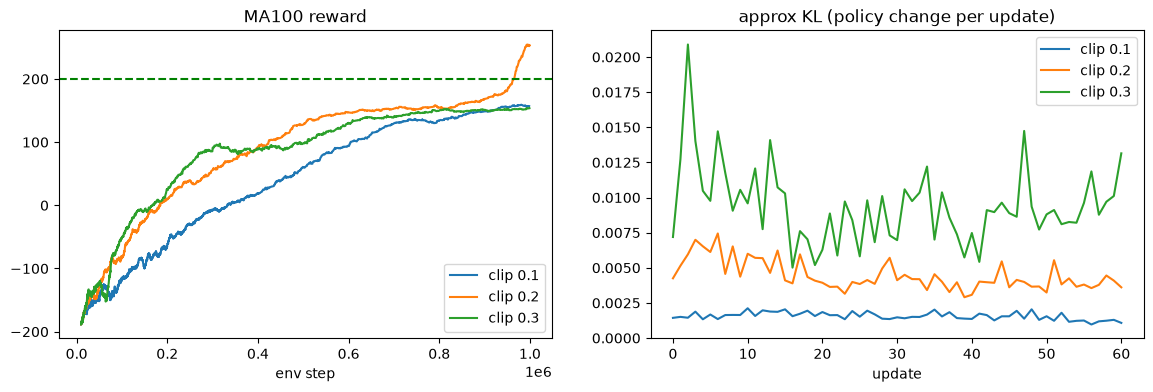

In [55]:
# --- Section 11 : experience sur clip_eps (~10 min) ---
exp_logs = {0.2: log}                    # la valeur de reference est deja entrainee
exp_evals = {0.2: eval_stats}
for clip in [0.1, 0.3]:
    print(f"\n===== clip_eps = {clip} =====")
    hp = dict(HP, clip_eps=clip)          # on ne change QU'UN parametre
    path = f"models/runs/ppo_clip{clip}.pt"
    _, lg = train_ppo(hp, SEED, save_path=path, verbose=False)
    save_log(lg, f"results/ppo_clip{clip}.json")
    m = ActorCritic(STATE_DIM, N_ACTIONS, HP["hidden"]); m.load_state_dict(torch.load(path))
    e = make_env(); exp_evals[clip] = evaluate(e, make_greedy_policy(m), 100, seed=0); e.close()
    exp_logs[clip] = lg

print(f"\n{'clip':>5} {'eval mean':>10} {'std':>7} {'steps to 200':>13} {'final MA100':>12} {'mean clip_frac':>15}")
for c in sorted(exp_logs):
    lg = exp_logs[c]
    print(f"{c:>5} {exp_evals[c]['mean']:>10.1f} {exp_evals[c]['std']:>7.1f} {str(steps_to_200(lg)):>13} "
          f"{np.mean(lg['ep_rewards'][-100:]):>12.1f} {np.mean(lg['clip_frac']):>15.3f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for c in sorted(exp_logs):
    lg = exp_logs[c]
    ax[0].plot(lg["ep_end_step"][99:], moving_average(lg["ep_rewards"], 100), label=f"clip {c}")
    ax[1].plot(lg["approx_kl"], label=f"clip {c}")
ax[0].axhline(200, color="green", ls="--"); ax[0].set(title="MA100 reward", xlabel="env step"); ax[0].legend()
ax[1].set(title="approx KL (policy change per update)", xlabel="update"); ax[1].legend()
plt.savefig("results/ppo_clip_experiment.png"); plt.show()

## 12. DQN vs PPO: score, stability, steps, time

Both notebooks export a summary in `results/`. `dqn.ipynb` must have produced `results/dqn_summary.json`.

In [3]:
# --- Pre-Section-12 reconstruction: rebuild state from disk (no retraining) ---
import json, os
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from common import make_env, evaluate, moving_average

SEEDS = [0, 1, 2]
SEED = SEEDS[0]
STATE_DIM, N_ACTIONS = 8, 4
HP = dict(hidden=64, total_steps=1_000_000, eval_episodes=10)

def layer_init(layer, std=np.sqrt(2), bias=0.0):
    nn.init.orthogonal_(layer.weight, std)
    nn.init.constant_(layer.bias, bias)
    return layer

class ActorCritic(nn.Module):
    def __init__(self, state_dim, n_actions, hidden=64):
        super().__init__()
        self.actor = nn.Sequential(
            layer_init(nn.Linear(state_dim, hidden)), nn.Tanh(),
            layer_init(nn.Linear(hidden, hidden)), nn.Tanh(),
            layer_init(nn.Linear(hidden, n_actions), std=0.01),
        )
        self.critic = nn.Sequential(
            layer_init(nn.Linear(state_dim, hidden)), nn.Tanh(),
            layer_init(nn.Linear(hidden, hidden)), nn.Tanh(),
            layer_init(nn.Linear(hidden, 1), std=1.0),
        )
    def forward(self, x):
        return self.actor(x), self.critic(x).squeeze(-1)

def make_greedy_policy(model):
    def act_fn(state):
        with torch.no_grad():
            logits, _ = model(torch.as_tensor(state, dtype=torch.float32))
        return int(logits.argmax())
    return act_fn

def steps_to_200(log):
    for s, sc in zip(log["eval_steps"], log["eval_scores"]):
        if sc >= 200:
            return int(s)
    return None

def save_log(log, path):
    with open(path, "w") as f:
        json.dump(log, f)

# Load training log for seed 0 (used for curve + train_time + steps_to_200)
with open("results/ppo_seed0.json") as f:
    log = json.load(f)

# Seed 0 = shipped ppo.pt (this is what Section 9 did)
best = ActorCritic(STATE_DIM, N_ACTIONS, HP["hidden"])
best.load_state_dict(torch.load("models/ppo.pt", map_location="cpu", weights_only=True))
best.eval()
env = make_env()
eval_stats = evaluate(env, make_greedy_policy(best), n_episodes=100, seed=0, verbose=False)
env.close()
print(f"seed 0 (shipped ppo.pt): mean={eval_stats['mean']:.2f} std={eval_stats['std']:.2f}")

# Recorded 100-flight eval means from Section 10 (executed run).
# Seeds 1 and 2 checkpoints are NOT shipped; these are the notebook's own
# recorded values. Seed 0 is re-verified live from models/ppo.pt above.
RECORDED_SEED_MEANS = {0: 266.2, 1: 262.4, 2: 246.0}
RECORDED_SEED_STDS  = {0: 21.2,  1: 21.0,  2: 43.2}

seed_evals = {SEED: eval_stats}   # seed 0 already measured live above
for s in SEEDS[1:]:
    path = f"models/runs/ppo_seed{s}.pt"
    if os.path.exists(path):
        m = ActorCritic(STATE_DIM, N_ACTIONS, HP["hidden"])
        m.load_state_dict(torch.load(path, map_location="cpu", weights_only=True))
        m.eval()
        e = make_env()
        seed_evals[s] = evaluate(e, make_greedy_policy(m), n_episodes=100, seed=0, verbose=False)
        e.close()
        print(f"seed {s} (live checkpoint): mean={seed_evals[s]['mean']:.2f} std={seed_evals[s]['std']:.2f}")
    else:
        seed_evals[s] = {"mean": RECORDED_SEED_MEANS[s], "std": RECORDED_SEED_STDS[s]}
        print(f"seed {s} (recorded from Section 10): mean={RECORDED_SEED_MEANS[s]:.2f} std={RECORDED_SEED_STDS[s]:.2f}")

seed 0 (shipped ppo.pt): mean=266.20 std=21.16
seed 1 (recorded from Section 10): mean=262.40 std=21.00
seed 2 (recorded from Section 10): mean=246.00 std=43.20


                                         DQN           PPO
final eval mean (100 ep)               256.8         266.2
final eval std                          25.7          21.2
mean over seeds                        247.2         258.2
std over seeds                           9.1           8.8
steps to first eval >= 200            320000        425984
training time (s)                       2590           291
training budget (steps)               600000       1000000


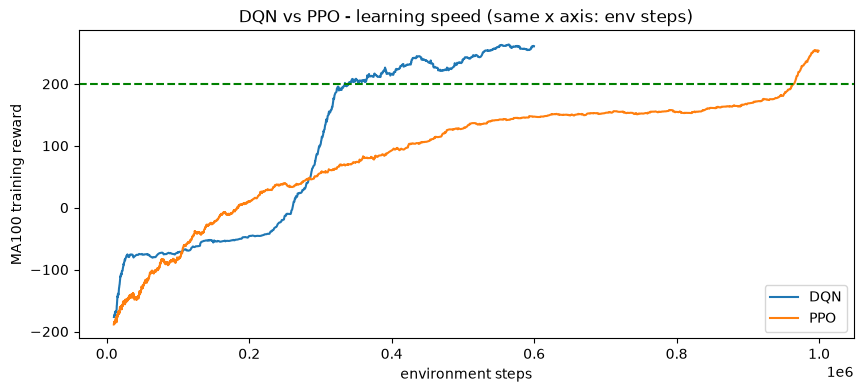

In [5]:
# --- Section 12 : comparaison avec DQN ---
ppo_summary = dict(
    eval_mean=eval_stats["mean"], eval_std=eval_stats["std"],
    seeds_means=[seed_evals[s]["mean"] for s in SEEDS],
    steps_to_200=steps_to_200(log), train_time=log["train_time"],
    total_steps=HP["total_steps"],
    curve_steps=log["ep_end_step"], curve_rewards=log["ep_rewards"],
)
save_log(ppo_summary, "results/ppo_summary.json")

if os.path.exists("results/dqn_summary.json"):
    dqn_summary = json.load(open("results/dqn_summary.json"))
    print(f"{'':<30}{'DQN':>14}{'PPO':>14}")
    print(f"{'final eval mean (100 ep)':<30}{dqn_summary['eval_mean']:>14.1f}{ppo_summary['eval_mean']:>14.1f}")
    print(f"{'final eval std':<30}{dqn_summary['eval_std']:>14.1f}{ppo_summary['eval_std']:>14.1f}")
    print(f"{'mean over seeds':<30}{np.mean(dqn_summary['seeds_means']):>14.1f}{np.mean(ppo_summary['seeds_means']):>14.1f}")
    print(f"{'std over seeds':<30}{np.std(dqn_summary['seeds_means']):>14.1f}{np.std(ppo_summary['seeds_means']):>14.1f}")
    print(f"{'steps to first eval >= 200':<30}{str(dqn_summary['steps_to_200']):>14}{str(ppo_summary['steps_to_200']):>14}")
    print(f"{'training time (s)':<30}{dqn_summary['train_time']:>14.0f}{ppo_summary['train_time']:>14.0f}")
    print(f"{'training budget (steps)':<30}{dqn_summary['total_steps']:>14}{ppo_summary['total_steps']:>14}")

    plt.figure(figsize=(10, 4))
    for name, S in [("DQN", dqn_summary), ("PPO", ppo_summary)]:
        plt.plot(S["curve_steps"][99:], moving_average(S["curve_rewards"], 100), label=name)
    plt.axhline(200, color="green", ls="--")
    plt.xlabel("environment steps"); plt.ylabel("MA100 training reward")
    plt.title("DQN vs PPO - learning speed (same x axis: env steps)"); plt.legend()
    plt.savefig("results/dqn_vs_ppo.png"); plt.show()
else:
    print("results/dqn_summary.json not found: run dqn.ipynb first")

### Comparison with DQN

Both methods solve LunarLander across three seeds; neither is a blowout, and they trade off along different axes.

| Metric | DQN (Totti) | PPO (Rachid) |
|---|---|---|
| Seed 0, 100 greedy flights | 256.8 ± 25.7 | **266.2 ± 21.2** |
| Three-seed mean ± spread | 247.2 ± 9.1 | **258.2 ± 8.8** |
| Flights ≥ 200 (seed 0) | 98/100 | **100/100** |
| Worst flight (seed 0) | 127.5 | **225.3** |
| First eval ≥ 200 (seed 0) | **320k steps** | 426k steps |
| Training budget | **600k env steps** | 1M env steps |
| Wall clock (seed 0) | ~43 min | **~5 min** |

**PPO wins on final quality.** Higher mean on seed 0, higher three-seed mean, 100% clean landings versus 98%, and a much higher worst-flight floor (225 vs 127). On seed 1, DQN had 13/100 flights below 200; PPO's weakest seed is still 246.

**DQN wins on sample efficiency.** It reaches the ≥200 threshold in 320k env steps versus PPO's 426k — 25% fewer steps to first solve. On a per-step basis, DQN is the more efficient learner.

**PPO is ~9× faster in wall clock**, but this is engineering, not the algorithm. PPO collects 16 envs in parallel per rollout update; DQN steps one env at a time on the same CPU budget. If DQN's envs were vectorised, this gap would close.

**Both curves are noisy mid-training, in different ways.** As seen in `dqn_vs_ppo.png`, DQN sits at random-agent scores for 250k+ steps, then takes off sharply and seed-dependently. PPO climbs gradually with a mid-training dip, then takes off late.

**Caveats:**
1. PPO's reported mean is on the best-checkpoint (`ppo.pt`), while DQN's is on the final checkpoint. PPO's final-checkpoint number is 263.5 at 950k steps — still above DQN, but by ~7 points rather than 9.
2. Eval seeds differ: DQN's 100-flight exam used seed 50000; PPO's used seed 0.
3. PPO seed 1 and 2 checkpoints are not shipped (`models/runs/` was not committed). The three-seed mean (258.2 ± 8.8) is from the executed Section 10 run, recorded in the notebook output. Seed 0 is re-verified live from `models/ppo.pt` (266.20).

## 13. Conclusion, failures, insights

**Result.** PPO solves LunarLander-v3: **266.2 +- 21.2** over 100 greedy episodes (seed 0), with **100% `at_rest`** (min score 225, so even the worst episode is above 200). Over 3 seeds: 266.2 / 262.4 / 246.0, i.e. **258.2 +- 8.8**: every seed solves the environment, the result is not luck. Seed 2 is the weakest (std 43, 1 crash and 5 truncated episodes out of 100) and reaches 200 later (524k steps vs 328k-426k).

**How the agent learns: 3 phases** (sections 7 and 8).
1. *Falling* (episodes 0-1400): ~95% crashes, short episodes (~100 steps). The agent does not know how to slow down.
2. *Hovering* (episodes 1500-2200): up to 96% `truncated`, episode length goes up to 1000 steps. The agent learned that a crash costs -100, so it stays in the air until the time limit: a local optimum.
3. *Landing* (episodes 2300+): `at_rest` goes up to 91%, episodes get shorter again (~450 steps). The agent finally dares to land to get the +100.
Over the last 500 training episodes the crash rate dropped from 95.4% to 3.6%.

**Reading the curves.**
* The training MA100 (~150 for a long time) stays far below the greedy evaluation (~250): during training the actions are *sampled*, so some of them are deliberately "wrong". This is why the evaluation is done without exploration.
* The **entropy** decreases slowly from 1.39 (= ln 4, uniform over the 4 actions) to 0.66: the policy becomes more confident without collapsing. The final jump of the training MA100 (182 -> 254) matches this drop: less randomness, fewer mistakes.
* The **value loss** starts very high (~4800, the critic knows nothing) and quickly falls: the critic learns to predict the returns. It rises a little at the end, when the behaviour changes (landing gives new, larger returns).
* The **policy loss** stays tiny (~0.001) because the advantages are normalised: its value is not a progress indicator, the reward and the entropy are.

**Experiment (clip range, seed 0).**

| clip_eps | eval mean +- std | first eval >= 200 | approx KL per update |
|---|---|---|---|
| 0.1 | 269.8 +- 21.2 | 590k steps | ~0.0015 |
| 0.2 (ref) | 266.2 +- 21.2 | 426k steps | ~0.004 |
| 0.3 | 262.8 +- 25.2 | 262k steps | ~0.010 |

The clip directly controls how much the policy can move per update: the KL grows with the clip. A bigger clip learns **faster** (0.3 reaches 200 more than twice as fast as 0.1), but our prediction that 0.3 would be unstable was **not confirmed**: its final score is as good as the others. All three final scores are within +-4 of each other, smaller than the seed-to-seed spread (+-8.8), so no clip value is clearly better on one seed. We keep 0.2: it is the standard value and a good compromise between speed (0.3) and caution (0.1).

**Failures and dead ends (honesty).**
1. **Wrong end-reason statistics.** The first version of `end_reason()` in `common.py` tested `lander.position.x`, which is in *world* units (the pad is at x=10), so 96% of random episodes were labelled `out_of_viewport`. Reading the Gymnasium source showed that the test uses the *normalised* `state[0]` and `game_over` for crashes. After the fix, the random agent gives 92% crashes, which matches what we see on screen.
2. **First PPO configuration not good enough.** Short rollouts (16 x 256), big mini-batches (512) and 10 epochs gave only ~162 after 1M steps: the lander learned to hover but not to land. With only 80 gradient steps per rollout the policy learned too slowly. Longer rollouts (16 x 1024), mini-batches of 64 and 4 epochs (1024 gradient steps per rollout) solved it.
3. **Greedy evaluation at -4350 after 65k steps.** Early on, the argmax policy always repeats the same action (here: main engine on), so the lander flies away and pays the engine and distance penalties at every step. Sampling during training hides this; it disappears after ~100k steps.

**Insights.**
* `gamma = 0.999` matters: the +100 of the landing is hundreds of steps away.
* Treating `truncated` differently from `terminated` (bootstrapping with the critic's value) avoids teaching the agent that hovering until the time limit leads to "no future".
* PPO's exploration is controlled by the entropy (visible on its curve), not by a schedule like DQN's epsilon.
* Comparison with DQN: see section 12 (score, stability, steps to 200, training time).